In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

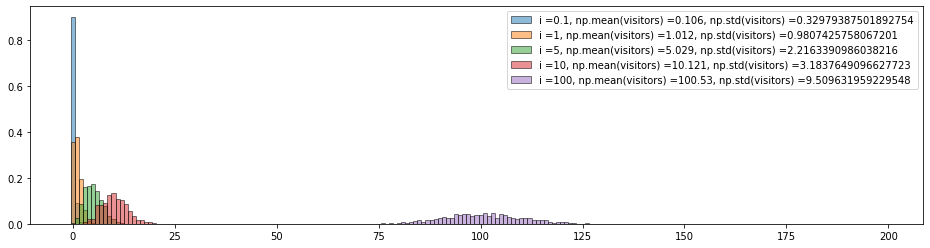

In [3]:
# Poisson, using random random
# chance of a random number between 0 and 1 being larger than mean/n (sum all n times)


def pool(m):
    size = 1_000
    n = np.empty(size)
    for i in range(size):        
        
        n[i] = np.random.random() < (m/size)
    return np.sum(n)


bins = np.arange(0,200)-0.5
plt.figure(figsize = [16,4])
for i in [0.1, 1,5,10, 100]:
    visitors = [pool(i) for _ in range(1_000)]
    plt.hist(
        visitors, 
        bins = bins, 
        ec = 'k', 
        alpha = 0.5,
        density = True,
        label = f'{i =}, {np.mean(visitors) =}, {np.std(visitors) =}')
    plt.legend()

plt.show()


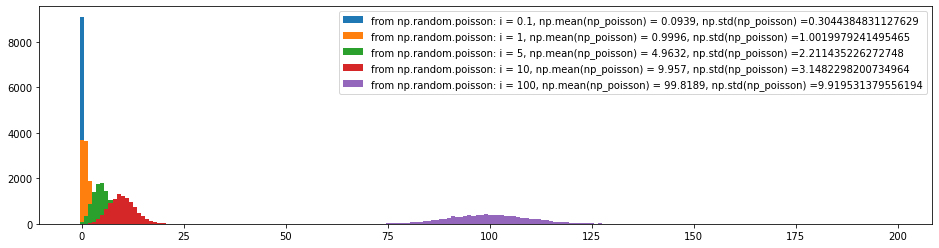

In [4]:
plt.figure(figsize = [16,4])
for i in [0.1, 1,5,10,100]:
    np_poisson = np.random.poisson(i, size = 10_000)    
    plt.hist(np_poisson, bins = bins, label = f'from np.random.poisson: {i = }, {np.mean(np_poisson) = }, {np.std(np_poisson) =}')    
    
    plt.legend()
plt.show()

In [5]:
# ecdf
def ecdf(data):
    x = np.sort(data) 
    y = np.arange(1, len(data) + 1) / len(data)
    return x,y

9.774989546902347 9.743559854378754 0.00011634823050432323 81.72445597818083


Text(0.5, 1.0, 'x: number from exp curve\n y: frequency, in pct')

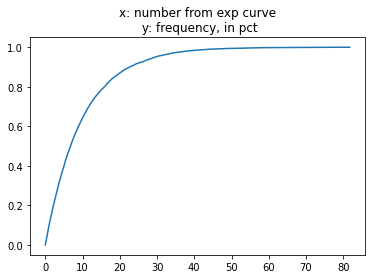

In [6]:
# Probability density function

# 1. np.random.exponential(scale, size):
# returns a random number from a exponential curve, with mean and std = 10
# [1,1,2,2,3,10,4,4,1,1,...]
# most frequent are the smallest ones - higher chance of happening at the beginning
# least frequent are the bigger ones - lower chance of happening at the end 
# -> (chance of happening * chance of not happening before)
np.random.seed(42)
lala = np.sort(np.random.exponential(scale = 10, size = 10000))
print(np.mean(lala), np.std(lala), np.min(lala), np.max(lala))

xnp, ynp = ecdf(lala)
plt.plot(xnp,ynp)
plt.title('x: number from exp curve\n y: frequency, in pct')

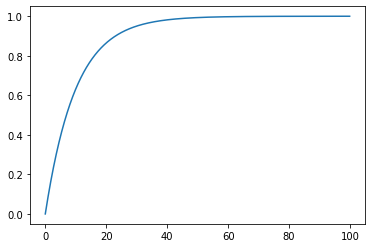

In [7]:
# cool formula (not taught on datacamp): F(x, mean) = 1 - np.exp(-x/mean)
# for each possible x, returns the probability of seeing x

def f1(x, mean):
    return 1 - np.exp(-x/mean)

xf = np.arange(0,100,0.1)
yf = [f1(i, 10) for i in xf]

plt.plot(xf,yf)

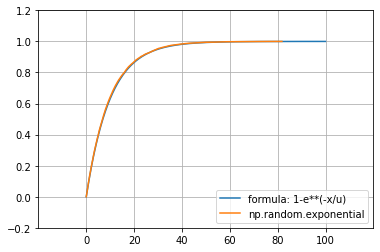

In [8]:
# final proof

plt.plot(xf, yf, label = 'formula: 1-e**(-x/u)')
plt.plot(xnp, ynp, label = 'np.random.exponential')
plt.grid()
plt.margins(0.2)
plt.legend()

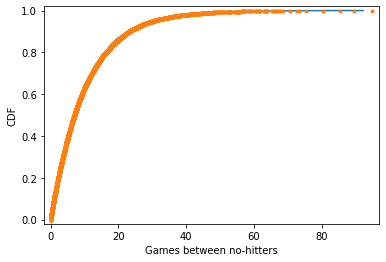

In [9]:
# Create an ECDF from real data: x, y
x, y = ecdf(np.random.exponential(scale = 10, size = 10_000))

# Create a CDF from theoretical samples: x_theor, y_theor
x_theor, y_theor = ecdf(np.random.exponential(scale = 10, size = 10_000))

# Overlay the plots
plt.plot(x_theor, y_theor)
plt.plot(x, y, marker='.', linestyle='none')

# Margins and axis labels
plt.margins(0.02)
plt.xlabel('Games between no-hitters')
plt.ylabel('CDF')

# Show the plot
plt.show()

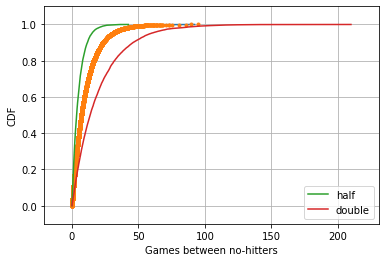

In [10]:
# Plot the theoretical CDFs
tau = 10
plt.plot(x_theor, y_theor)
plt.plot(x, y, marker='.', linestyle='none')
plt.margins(0.02)
plt.xlabel('Games between no-hitters')
plt.ylabel('CDF')

# Take samples with half tau: samples_half
samples_half = np.random.exponential(tau/2,10_000)

# Take samples with double tau: samples_double
samples_double = np.random.exponential(tau*2,10_000)

# Generate CDFs from these samples
x_half, y_half = ecdf(samples_half)
x_double, y_double = ecdf(samples_double)

# Plot these CDFs as lines
_ = plt.plot(x_half, y_half, label = 'half')
_ = plt.plot(x_double, y_double, label = 'double')

# Show the plot
plt.legend()
plt.margins(0.1)
plt.grid()
plt.show()

max fertility: 7.069
-0.8041324026815345 -0.8041324026815344 -0.8041324026815344


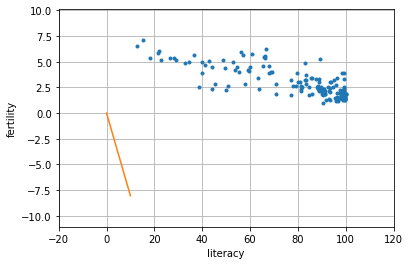

In [11]:
# EDA of literacy/fertility data
# source: https://www.eea.europa.eu/data-and-maps/figures/correlation-between-fertility-and-female-education
file = 'TREND01-5G-educ-fertility-bubbles.xls'

sheets = pd.ExcelFile(file).sheet_names
df = pd.read_excel(file, sheet_name = sheets[0]).iloc[6:,[0,1,2,3]]

df.columns = df.iloc[0,:]
df.columns.name = None
df = df.iloc[1:,:]
for col in ['female literacy','fertility']:
    df[col] = pd.to_numeric(df[col], errors = 'coerce')

df = df.dropna()

print('max fertility:', df['fertility'].max())

fertility = df['fertility'].values
illiteracy = df['female literacy'].values


pearson1 = df.corr().loc['fertility','female literacy']
pearson2 = np.corrcoef(fertility, illiteracy)[0,1]
pearson3 = (np.cov(fertility, illiteracy, ddof = 0)/(np.std(fertility)*np.std(illiteracy)))[0][1]
print(pearson1, pearson2, pearson3)


pearson_line = np.array([0,10])*pearson1



plt.plot(df['female literacy'], df['fertility'], marker = '.', linestyle = 'none')
plt.plot([0,10], pearson_line)
plt.xlabel('literacy')
plt.ylabel('fertility')
plt.grid()
plt.margins(0.2)




-0.04979854809063421 6.867905419699976
least squares: 
slope =-0.05; 
residual = 6.87 


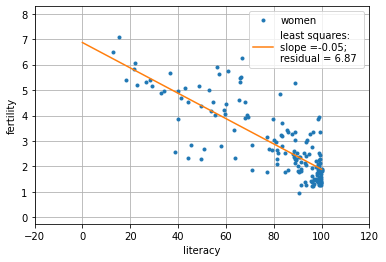

In [12]:
# Least squares (2 columns): np.polyfit
a,b = np.polyfit(
    x = illiteracy,
    y = fertility, 
    deg = 1)
print(a,b)
x = np.array([0,100])
y = x * a + b


plt.plot(illiteracy, fertility, marker = '.', linestyle = 'none', label = 'women')
label = f'least squares: \nslope ={round(a,2)}; \nresidual = {round(b,2)} '
plt.plot(x,y, label = label )
plt.xlabel('literacy')
plt.ylabel('fertility')
plt.grid()
plt.legend()
plt.margins(0.2)
print(label)

array([-0.04952476])

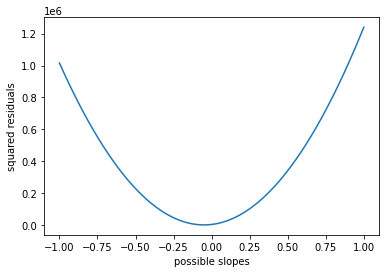

In [13]:
# slope (a) = -0.05; resudual (b) = 6.87
# estimated fertility = female literacy * slope + b 

# what would be the sum of residuals for different slopes?

theor_slopes = np.linspace(-1,1,2000)
l = []
for i in theor_slopes:
    est_fertility = illiteracy*i + b
    arr_res = (fertility - est_fertility)**2
    res = np.sum(arr_res)
    l.append(res)
l = np.array(l)    
plt.plot(theor_slopes, l)

plt.ylabel('squared residuals')
plt.xlabel('possible slopes')
theor_slopes[l == min(l)]

In [14]:
# trying least squares using different formula
x = np.vstack(
    [illiteracy, np.ones(len(illiteracy))]
    ).T
y = fertility

np.linalg.lstsq(x,y)

/tmp/ipykernel_10225/2017986326.py:7: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  np.linalg.lstsq(x,y)


(array([-0.04979855,  6.86790542]),
 array([115.94926252]),
 2,
 array([1060.79837053,    3.50957105]))

In [15]:
# Anscombe's quartet
site = "https://en.wikipedia.org/wiki/Anscombe's_quartet"
df = pd.read_html(site)[1]
for i in range(0,7,2):
    df.iloc[0,[i,i+1]] = df.iloc[0,[i,i+1]] + str(int(i/2 + 1))
df.columns = df.iloc[0,:]
df = df.iloc[1:]
for col in df:
    df[col] = pd.to_numeric(df[col])
df

,x1,y1,x2,y2,x3,y3,x4,y4
1,10.0,8.04,10.0,9.14,10.0,7.46,8.0,6.58
2,8.0,6.95,8.0,8.14,8.0,6.77,8.0,5.76
3,13.0,7.58,13.0,8.74,13.0,12.74,8.0,7.71
4,9.0,8.81,9.0,8.77,9.0,7.11,8.0,8.84
5,11.0,8.33,11.0,9.26,11.0,7.81,8.0,8.47
6,14.0,9.96,14.0,8.10,14.0,8.84,8.0,7.04
7,6.0,7.24,6.0,6.13,6.0,6.08,8.0,5.25
8,4.0,4.26,4.0,3.10,4.0,5.39,19.0,12.50
9,12.0,10.84,12.0,9.13,12.0,8.15,8.0,5.56
10,7.0,4.82,7.0,7.26,7.0,6.42,8.0,7.91


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11 entries, 1 to 11
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      11 non-null     float64
 1   y1      11 non-null     float64
 2   x2      11 non-null     float64
 3   y2      11 non-null     float64
 4   x3      11 non-null     float64
 5   y3      11 non-null     float64
 6   x4      11 non-null     float64
 7   y4      11 non-null     float64
dtypes: float64(8)
memory usage: 836.0 bytes


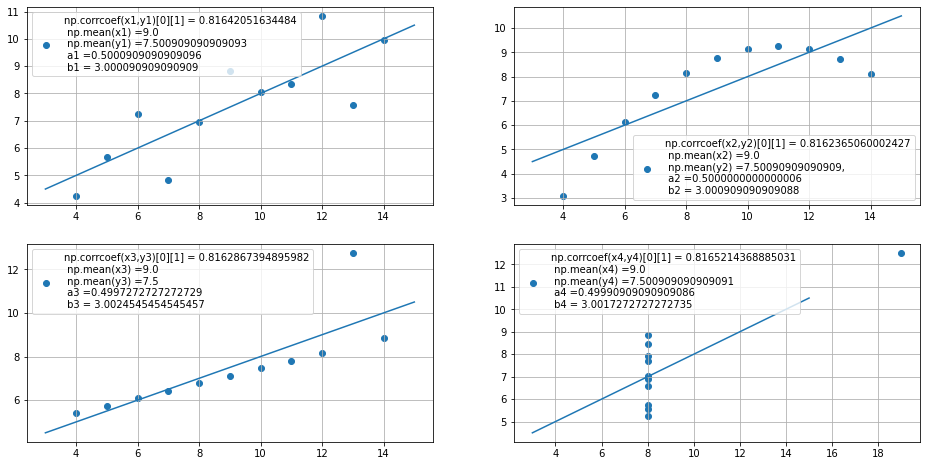

In [17]:
# Anscombe: all charts
for i in range(1,5):
    globals()[f'x{i}'] = df[f'x{i}'].values
    globals()[f'y{i}'] = df[f'y{i}'].values

fig, ax = plt.subplots(2,2, figsize = [16,8])

a1,b1 = np.polyfit(x1,y1, deg = 1)
a2,b2 = np.polyfit(x2,y2, deg = 1)
a3,b3 = np.polyfit(x3,y3, deg = 1)
a4,b4 = np.polyfit(x4,y4, deg = 1)
arr = np.array([3,15])

ax[0,0].scatter(x1,y1)
ax[0,0].legend([f'{np.corrcoef(x1,y1)[0][1] = }\n {np.mean(x1) =}\n {np.mean(y1) =} \n {a1 =}\n {b1 = }'])
ax[0,0].plot(arr, arr*a1 + b1)
ax[0,0].grid()

ax[0,1].scatter(x2,y2)
ax[0,1].plot(arr, arr*a2 + b2)
ax[0,1].grid()
ax[0,1].legend([f'{np.corrcoef(x2,y2)[0][1] = }\n {np.mean(x2) =}\n {np.mean(y2) =},\n {a2 =}\n {b2 = }'])

ax[1,0].scatter(x3,y3)
ax[1,0].plot(arr, arr*a3 + b3)
ax[1,0].grid()
ax[1,0].legend([f'{np.corrcoef(x3,y3)[0][1] = }\n {np.mean(x3) =}\n {np.mean(y3) =} \n {a3 =}\n {b3 = }'])

ax[1,1].scatter(x4,y4)
ax[1,1].plot(arr, arr*a4 + b4)
ax[1,1].grid()
ax[1,1].legend([f'{np.corrcoef(x4,y4)[0][1] = }\n {np.mean(x4) =}\n {np.mean(y4) =} \n {a4 =}\n {b4 = }'])
plt.show()



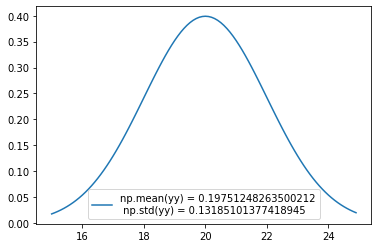

In [18]:
# Normal distribution formula
m = 20
std = 2
a = m-5
b = m+5


def norm(x):
    return np.exp(-(x**2)/2)/np.sqrt(2*np.pi)

def norm2(x, mean=m):
    return np.exp(-(((x-mean)/std)**2)/2)/np.sqrt(2*np.pi)

x = np.arange(a,b,0.1)
yy = list(map(norm2, np.arange(a,b,0.1)))

plt.plot(x,yy)
plt.legend([f'{np.mean(yy) = }\n {np.std(yy) = }'])

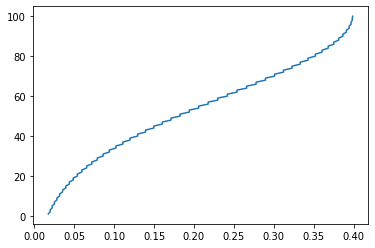

In [19]:
def ecdf(data):
    l = len(data)
    x = np.sort(data)
    y = np.arange(1, l+1)/l*100
    return x,y

x,y = ecdf(yy)
plt.plot(x,y)

In [20]:
def bootstrap_replicate_1d(data, func):
    """Generate bootstrap replicate of 1d data"""
    bs_sample = np.random.choice(data, len(data))
    return func(bs_sample)

def draw_bs_reps(data, func, size=1):
    """draw bootstrap replicates"""
    
    # initialize array of replicates: bs_replicates
    bs_replicates = np.empty(shape = size)
    
    # Generate replicates
    for i in range(size):
        bs_replicates[i] = bootstrap_replicate_1d(data,func)
            
    return bs_replicates

In [21]:
rainfall =  [875.5,  648.2,  788.1,  940.3,  491.1,  743.5,  730.1,  686.5,
        878.8,  865.6,  654.9,  831.5,  798.1,  681.8,  743.8,  689.1,
        752.1,  837.2,  710.6,  749.2,  967.1,  701.2,  619. ,  747.6,
        803.4,  645.6,  804.1,  787.4,  646.8,  997.1,  774. ,  734.5,
        835. ,  840.7,  659.6,  828.3,  909.7,  856.9,  578.3,  904.2,
        883.9,  740.1,  773.9,  741.4,  866.8,  871.1,  712.5,  919.2,
        927.9,  809.4,  633.8,  626.8,  871.3,  774.3,  898.8,  789.6,
        936.3,  765.4,  882.1,  681.1,  661.3,  847.9,  683.9,  985.7,
        771.1,  736.6,  713.2,  774.5,  937.7,  694.5,  598.2,  983.8,
        700.2,  901.3,  733.5,  964.4,  609.3, 1035.2,  718. ,  688.6,
        736.8,  643.3, 1038.5,  969. ,  802.7,  876.6,  944.7,  786.6,
        770.4,  808.6,  761.3,  774.2,  559.3,  674.2,  883.6,  823.9,
        960.4,  877.8,  940.6,  831.8,  906.2,  866.5,  674.1,  998.1,
        789.3,  915. ,  737.1,  763. ,  666.7,  824.5,  913.8,  905.1,
        667.8,  747.4,  784.7,  925.4,  880.2, 1086.9,  764.4, 1050.1,
        595.2,  855.2,  726.9,  785.2,  948.8,  970.6,  896. ,  618.4,
        572.4, 1146.4,  728.2,  864.2,  793. ]

In [22]:
# standard error of the mean: 
sem = np.std(rainfall) / np.sqrt(len(rainfall))

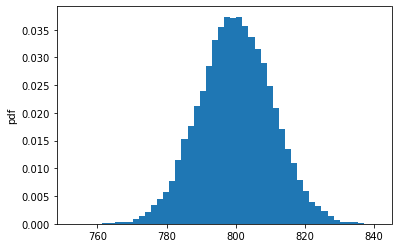

In [23]:
bs_replicates = draw_bs_reps(rainfall, np.mean, size = 30_000)
plt.hist(bs_replicates, bins = 50, density = True)
plt.ylabel('pdf')
plt.show()

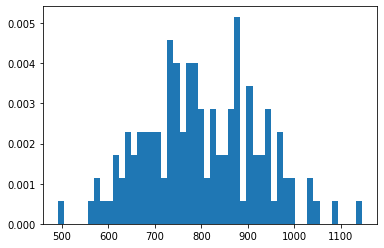

In [24]:
plt.hist(rainfall, bins = 50, density = True)
plt.show()

In [25]:
len(rainfall)

133

In [26]:
# confidence interval
np.percentile(bs_replicates, [2.5, 97.5])

array([779.40975564, 820.75140977])

In [27]:
bs_reps = draw_bs_reps(data = rainfall, func = np.var, size = 10_000)/100

145.88993574434508
[114.59129616 134.22990494 145.23411114 156.85570086 180.46504534]


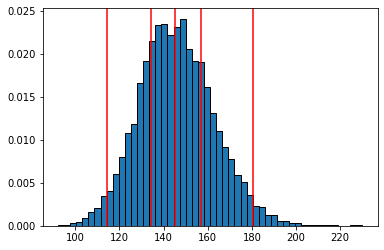

In [28]:
plt.hist(bs_reps, ec = 'k', bins = 50, density = True)
print(np.mean(bs_reps))
print(np.percentile(bs_reps, [2.5,25,50,75,97.5]))
for x in np.percentile(bs_reps, [2.5,25,50,75,97.5]):
    plt.axvline(x, color = 'red')

plt.show()

In [29]:
def draw_bs_pairs_linreg(x, y, size=1):
    """Perform pairs bootstrap for linear regression."""

    # Set up array of indices to sample from: inds
    # (in other words, select random pairs from each pair of illiteracy and fertility)
    inds = np.arange(0,len(x))

    # Initialize replicates: bs_slope_reps, bs_intercept_reps
    # (in other words: instead of appending values to empty list, create np.empty lists with right shape)
    # (remember you are adding to these lists each result per size. In other words: one slope and one intercept per size range)
    bs_slope_reps = np.empty(size)
    bs_intercept_reps = np.empty(size)

    # Generate replicates
    for i in range(size):
        bs_inds = np.random.choice(inds, size=len(inds))        
        bs_x, bs_y = x[bs_inds], y[bs_inds]
        
        bs_slope_reps[i], bs_intercept_reps[i] = np.polyfit(bs_x, bs_y, 1)

    return bs_slope_reps, bs_intercept_reps

    
x = np.array([1,2,4,6]) 
y = np.array([3,5,7,11])
size = 5
xx = list(x)


draw_bs_pairs_linreg(x,y, size)

(array([1.55932203, 2.        , 1.6119403 , 1.6119403 , 1.52542373]),
 array([ 1.71186441, -1.        ,  1.14925373,  1.14925373,  1.54237288]))

[-0.05534064 -0.04417467]


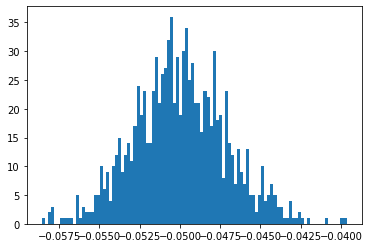

In [30]:
bs_slope, bs_interc = draw_bs_pairs_linreg(illiteracy, fertility, 1000)
print(np.percentile(bs_slope, [2.5, 97.5]))
plt.hist(bs_slope, bins = 100)
plt.show()

In [31]:
x,y = np.polyfit(illiteracy, fertility, 1)
x,y

(-0.04979854809063421, 6.867905419699976)

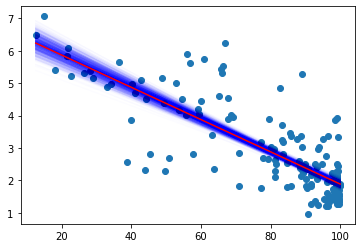

In [32]:
plt.scatter(illiteracy, fertility)

for bs_x, bs_y in zip(bs_slope, bs_interc):
    plt.plot([min(illiteracy), max(illiteracy)],[min(illiteracy)*bs_x + bs_y, max(illiteracy)*bs_x + bs_y], color = 'blue', alpha = 0.01)
plt.plot([min(illiteracy), max(illiteracy)],[min(illiteracy)*x + y, max(illiteracy)*x + y], color = 'red')
plt.show()

In [33]:
# kind of confused... permutation to see if samples are equal or different
# the idea is that, if the data are similar, the permutation of the data should result similar curves
# if the data is very different, the permutation should result a differnt beast altogether

rain_june = np.array([ 66.2,  39.7,  76.4,  26.5,  11.2,  61.8,   6.1,  48.4,  89.2,
       104. ,  34. ,  60.6,  57.1,  79.1,  90.9,  32.3,  63.8,  78.2,
        27.5,  43.4,  30.1,  17.3,  77.5,  44.9,  92.2,  39.6,  79.4,
        66.1,  53.5,  98.5,  20.8,  55.5,  39.6,  56. ,  65.1,  14.8,
        13.2,  88.1,   8.4,  32.1,  19.6,  40.4,   2.2,  77.5, 105.4,
        77.2,  38. ,  27.1, 111.8,  17.2,  26.7,  23.3,  77.2,  87.2,
        27.7,  50.6,  60.3,  15.1,   6. ,  29.4,  39.3,  56.3,  80.4,
        85.3,  68.4,  72.5,  13.3,  28.4,  14.7,  37.4,  49.5,  57.2,
        85.9,  82.1,  31.8, 126.6,  30.7,  41.4,  33.9,  13.5,  99.1,
        70.2,  91.8,  61.3,  13.7,  54.9,  62.5,  24.2,  69.4,  83.1,
        44. ,  48.5,  11.9,  16.6,  66.4,  90. ,  34.9, 132.8,  33.4,
       225. ,   7.6,  40.9,  76.5,  48. , 140. ,  55.9,  54.1,  46.4,
        68.6,  52.2, 108.3,  14.6,  11.3,  29.8, 130.9, 152.4,  61. ,
        46.6,  43.9,  30.9, 111.1,  68.5,  42.2,   9.8, 285.6,  56.7,
       168.2,  41.2,  47.8, 166.6,  37.8,  45.4,  43.2])

rain_november = np.array([ 83.6,  30.9,  62.2,  37. ,  41. , 160.2,  18.2, 122.4,  71.3,
        44.2,  49.1,  37.6, 114.5,  28.8,  82.5,  71.9,  50.7,  67.7,
       112. ,  63.6,  42.8,  57.2,  99.1,  86.4,  84.4,  38.1,  17.7,
       102.2, 101.3,  58. ,  82. , 101.4,  81.4, 100.1,  54.6,  39.6,
        57.5,  29.2,  48.8,  37.3, 115.4,  55.6,  62. ,  95. ,  84.2,
       118.1, 153.2,  83.4, 104.7,  59. ,  46.4,  50. , 147.6,  76.8,
        59.9, 101.8, 136.6, 173. ,  92.5,  37. ,  59.8, 142.1,   9.9,
       158.2,  72.6,  28. , 112.9, 119.3, 199.2,  50.7,  44. , 170.7,
        67.2,  21.4,  61.3,  15.6, 106. , 116.2,  42.3,  38.5, 132.5,
        40.8, 147.5,  93.9,  71.4,  87.3, 163.7, 141.4,  62.6,  84.9,
        28.8, 121.1,  28.6,  32.4, 112. ,  50. ,  96.9,  81.8,  70.4,
       117.5,  41.2, 124.9,  78.2,  93. ,  53.5,  50.5,  42.6,  47.9,
        73.1, 129.1,  56.9, 103.3,  60.5, 134.3,  93.1,  49.5,  48.2,
       167.9,  27. , 111.1,  55.4,  36.2,  57.4,  66.8,  58.3,  60. ,
       161.6, 112.7,  37.4, 110.6,  56.6,  95.8, 126.8])

In [34]:
# p-value

'''
A p-value is the probability that:
- random chance generated the data,
- or something else that is equal
- or rarer
'''

'h0: the odds of getting hh tossing a coin twice is common'
p = [''.join(sorted([x,y])) for x in 'ht' for y in 'ht']
probs = {x:p.count(x) for x in p}
all_possibilities = np.sum([probs[k] for k in probs.keys()])

print(f"all possibilities: {all_possibilities}")
print(f'probability of getting hh: {probs["hh"]/all_possibilities = }')
print(f"p_value of getting hh:{(probs['hh'] + probs['tt'])/all_possibilities}")




all possibilities: 4
probability of getting hh: probs["hh"]/all_possibilities = 0.25
p_value of getting hh:0.5


In [35]:
'h0: the odds of getting hhhht tossing a coin five times is common'
p = [
    ''.join(sorted([a,b,c,d,e])) 
    for a in 'ht'
    for b in 'ht'
    for c in 'ht'
    for d in 'ht'
    for e in 'ht'
    ]

probs = {x:p.count(x) for x in p}
all_possibilities = np.sum([probs[k] for k in probs.keys()])

print(f"all possibilities: {all_possibilities}")
print(f'probability of getting hhhhh: {probs["hhhhh"]/all_possibilities = }')
print(f'probability of getting hhhht: {probs["hhhht"]/all_possibilities = }')
print(f"p_value of getting hh:\n{(probs['hhhht']+ probs['htttt']+ probs['hhhhh']+probs['ttttt'])/all_possibilities = }")



all possibilities: 32
probability of getting hhhhh: probs["hhhhh"]/all_possibilities = 0.03125
probability of getting hhhht: probs["hhhht"]/all_possibilities = 0.15625
p_value of getting hh:
(probs['hhhht']+ probs['htttt']+ probs['hhhhh']+probs['ttttt'])/all_possibilities = 0.375


In [36]:
'lala'.split()

['lala']

In [37]:
# permutation sample function (so we can permutate values to generate p-values)

def permutation_sample(data1, data2):
    """Generate a permutation sample from two data sets"""
    
    # Concatenate the data sets: data
    data = np.concatenate((data1, data2))
    
    # Permute the concatenated array: permuted_data
    permuted_data = np.random.permutation(data)
    
    # Split the permuted array into two: perm_sample_1, perm_sample:2
    perm_sample_1 = permuted_data[:len(data1)]
    perm_sample_2 = permuted_data[len(data1):]
    
    return perm_sample_1, perm_sample_2

permutation_sample([1,2,3],[4,5,6,7])

(array([3, 4, 2]), array([7, 6, 1, 5]))

In [38]:
def draw_perm_reps(data_1, data_2, func, size=1):
    """Generate multiple permutation replicates."""
    
    # Initialize array of replicates: perm_replicates
    perm_replicates = np.empty(size)
    
    for i in range(size):
        # Generate permutation sample
        perm_sample_1, perm_sample_2 = permutation_sample(data_1, data_2)
        
        # Comute the test statistic        
        perm_replicates[i] = func(perm_sample_1, perm_sample_2)
   
    return perm_replicates

a = np.random.binomial(10,0.5,20)
b = np.random.binomial(10,0.4,20)

def diff_of_means(data_1, data_2):
    diff = np.mean(data_1) - np.mean(data_2)
    return diff


real = diff_of_means(a,b)
est = draw_perm_reps(a,b, diff_of_means, size = 1000)
total_p = [est >= real]
a,b,np.mean(a), np.mean(b), real, np.sum(est)/len(est), np.sum(total_p)/ len(est)

(array([4, 7, 7, 4, 5, 4, 3, 6, 7, 6, 3, 7, 3, 4, 7, 5, 4, 5, 4, 4]),
 array([2, 4, 3, 5, 3, 6, 5, 4, 4, 5, 5, 4, 5, 6, 2, 5, 3, 4, 5, 5]),
 4.95,
 4.25,
 0.7000000000000002,
 0.010399999999999994,
 0.062)

In [39]:
# p-value: compare two datasets - frog tongue strike force
# h0: distribution of strike forces is identical
force_a = np.array([1.612, 0.605, 0.327, 0.946, 0.541, 1.539, 0.529, 0.628, 1.453,
       0.297, 0.703, 0.269, 0.751, 0.245, 1.182, 0.515, 0.435, 0.383,
       0.457, 0.73 ])

force_b = np.array([0.172, 0.142, 0.037, 0.453, 0.355, 0.022, 0.502, 0.273, 0.72 ,
       0.582, 0.198, 0.198, 0.597, 0.516, 0.815, 0.402, 0.605, 0.711,
       0.614, 0.468])

# real, empirical diff of means
empirical_diff_means = diff_of_means(force_a,force_b)
np.mean(force_a), np.mean(force_b), empirical_diff_means
# force b < force a. How many permutation replicates are equal to the smaller, or even smaller?
# or, how many have a difference of mean evel larger?

(0.7073500000000001, 0.4191000000000001, 0.28825000000000006)

In [40]:
# permutation test
np.random.seed(42)
perm_replicates = draw_perm_reps(force_a, force_b, diff_of_means, size = 10_000)
bigger_diff = np.sum(perm_replicates >= empirical_diff_means)
p = np.sum(bigger_diff) / len(perm_replicates)
bigger_diff, p
# 63/10_000 ... small ... the samples are different. Frog A is stronger!

(63, 0.0063)

In [41]:
# bootstrap hypothesis test
# if you don't have a dog, you bootstrap it

# new frog: no data set. Just a mean: 0.55 N

new_frog_mean = 0.55

# create a fake dataset for new_frog, based on frog b (same std from frog b)
translated_force_b = force_b - np.mean(force_b) + new_frog_mean

# create bootstrap replicates from 'fake' new frog, and its mean
bs_replicates = draw_bs_reps(translated_force_b, np.mean, 10_000)

# how many of these replicates are less than observed from frog B?

p = np.sum(bs_replicates <= np.mean(force_b))/10_000
np.mean(force_b), new_frog_mean, np.mean(translated_force_b), np.sum(bs_replicates <= np.mean(force_b)), p
# 65 / 10_000 'fake' replicates of the new frog are of equal rarity or rarer
# the samples are different
# still have questions

(0.4191000000000001, 0.55, 0.5499999999999999, 61, 0.0061)

In [42]:
# distribution of impact force: is this the same?
# hypothesis: the means of the frog tongues impact are equal


# Compute mean of all forces: mean_force
forces_concat = np.concatenate([force_a, force_b])
mean_force = np.mean(forces_concat)

# Generate shifted arrays
force_a_shifted = force_a - np.mean(force_a) + mean_force
force_b_shifted = force_b - np.mean(force_b) + mean_force 

# Compute 10,000 bootstrap replicates from shifted arrays
bs_replicates_a = draw_bs_reps(force_a_shifted, np.mean, 10_000)
bs_replicates_b = draw_bs_reps(force_b_shifted, np.mean, 10_000)

# Get replicates of difference of means: bs_replicates
bs_replicates = (bs_replicates_a - bs_replicates_b) >= empirical_diff_means

# Compute and print p-value: p
p = np.sum(bs_replicates) / 10_000
print('p-value =', p)

np.mean(force_a), np.mean(force_b),np.mean(force_a) - np.mean(force_b), empirical_diff_means


p-value = 0.0048


(0.7073500000000001,
 0.4191000000000001,
 0.28825000000000006,
 0.28825000000000006)

In [43]:
_ = """

dataset_a 
dataset_b

dataset_ab

shift_ds_a = dataset_a - mean(dataset_a) + mean(dataset_ab)
shift_ds_b = dataset_b - mean(dataset_b) + mean(dataset_ab)

10_000 times:
bs_replicates_a = bootstrap(shift_ds_a)
bs_replicates_b = bootstrap(shift_ds_b)

if np.mean(dataset_a) > np.mean(dataset_b):
- diff_mean_bs_empirical = bs_replicates_a - bs_replicates_b >= mean(dataset_a) - mean(dataset_b)
- p = sum(diff_mean_bs_empirical)/10_000
"""

In [44]:
a = [1,2,3]
b = [1,2,3,2,1,2,3,2,1,2,3]

x = np.concatenate([a,b])
y = np.random.permutation(x)

aa = y[:len(a)]
bb = y[len(a):]

a,b,x,y,aa,bb

([1, 2, 3],
 [1, 2, 3, 2, 1, 2, 3, 2, 1, 2, 3],
 array([1, 2, 3, 1, 2, 3, 2, 1, 2, 3, 2, 1, 2, 3]),
 array([1, 1, 2, 1, 2, 2, 2, 3, 2, 3, 3, 3, 2, 1]),
 array([1, 1, 2]),
 array([1, 2, 2, 2, 3, 2, 3, 3, 3, 2, 1]))

In [45]:
np.mean(a), np.mean(b), np.mean(y), np.mean(aa), np.mean(bb)

(2.0, 2.0, 2.0, 1.3333333333333333, 2.1818181818181817)

In [46]:
nht_dead = np.array([  -1,  894,   10,  130,    1,  934,   29,    6,  485,  254,  372,
         81,  191,  355,  180,  286,   47,  269,  361,  173,  246,  492,
        462, 1319,   58,  297,   31, 2970,  640,  237,  434,  570,   77,
        271,  563, 3365,   89,    0,  379,  221,  479,  367,  628,  843,
       1613, 1101,  215,  684,  814,  278,  324,  161,  219,  545,  715,
        966,  624,   29,  450,  107,   20,   91, 1325,  124, 1468,  104,
       1309,  429,   62, 1878, 1104,  123,  251,   93,  188,  983,  166,
         96,  702,   23,  524,   26,  299,   59,   39,   12,    2,  308,
       1114,  813,  887])

nht_live = np.array([ 645, 2088,   42, 2090,   11,  886, 1665, 1084, 2900, 2432,  750,
       4021, 1070, 1765, 1322,   26,  548, 1525,   77, 2181, 2752,  127,
       2147,  211,   41, 1575,  151,  479,  697,  557, 2267,  542,  392,
         73,  603,  233,  255,  528,  397, 1529, 1023, 1194,  462,  583,
         37,  943,  996,  480, 1497,  717,  224,  219, 1531,  498,   44,
        288,  267,  600,   52,  269, 1086,  386,  176, 2199,  216,   54,
        675, 1243,  463,  650,  171,  327,  110,  774,  509,    8,  197,
        136,   12, 1124,   64,  380,  811,  232,  192,  731,  715,  226,
        605,  539, 1491,  323,  240,  179,  702,  156,   82, 1397,  354,
        778,  603, 1001,  385,  986,  203,  149,  576,  445,  180, 1403,
        252,  675, 1351, 2983, 1568,   45,  899, 3260, 1025,   31,  100,
       2055, 4043,   79,  238, 3931, 2351,  595,  110,  215,    0,  563,
        206,  660,  242,  577,  179,  157,  192,  192, 1848,  792, 1693,
         55,  388,  225, 1134, 1172, 1555,   31, 1582, 1044,  378, 1687,
       2915,  280,  765, 2819,  511, 1521,  745, 2491,  580, 2072, 6450,
        578,  745, 1075, 1103, 1549, 1520,  138, 1202,  296,  277,  351,
        391,  950,  459,   62, 1056, 1128,  139,  420,   87,   71,  814,
        603, 1349,  162, 1027,  783,  326,  101,  876,  381,  905,  156,
        419,  239,  119,  129,  467])

# Compute the observed difference in mean inter-no-hitter times: nht_diff_obs
nht_diff_obs = diff_of_means(nht_dead, nht_live)

# Acquire 10,000 permutation replicates of difference in mean no-hitter time: perm_replicates
perm_replicates = draw_perm_reps(nht_dead,nht_live,diff_of_means,10_000)


# Compute and print the p-value: p
p = np.sum(perm_replicates <= np.mean(nht_diff_obs))/len(perm_replicates)
print('p-val =', p)

p-val = 0.0


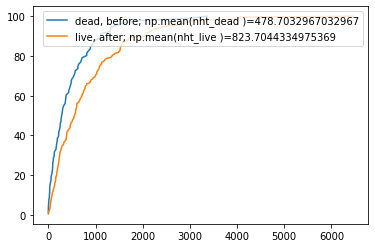

In [53]:
x1,y1 = ecdf(nht_dead)
x2,y2 = ecdf(nht_live)

plt.plot(x1,y1, label = f'dead, before; {np.mean(nht_dead )=}')
plt.plot(x2,y2, label = f'live, after; {np.mean(nht_live )=}')
plt.legend()

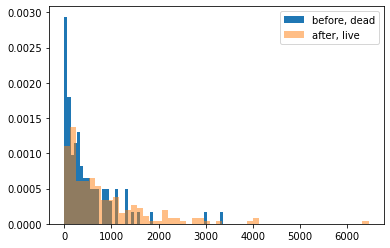

In [61]:
plt.hist(nht_dead, alpha = 1, bins = 50, density = True, label = 'before, dead')
plt.hist(nht_live, alpha = 0.5,  bins = 50, density = True, label = 'after, live')
plt.legend()

In [65]:
## illiteracy vs fertility: random?

# Compute observed correlation: r_obs
r_obs = np.corrcoef(illiteracy, fertility)[0,1]

# Initialize permutation replicates: perm_replicates
perm_replicates = np.empty(10000)

# Draw replicates
for i in range(10_000):
    # Permute illiteracy measurments: illiteracy_permuted
    illiteracy_permuted = np.random.permutation(illiteracy)

    # Compute Pearson correlation
    perm_replicates[i] = np.corrcoef(illiteracy_permuted, fertility)[0,1]

# Compute p-value: p
p = np.sum(r_obs >= perm_replicates )/len(perm_replicates)
print('p-val =', p)
print('guess not...')

p-val = 0.0
guess not...


In [67]:
## Bee sperm: bootstrap p-value

control = np.array([ 4.159234,  4.408002,  0.172812,  3.498278,  3.104912,  5.164174,
        6.615262,  4.633066,  0.170408,  2.65    ,  0.0875  ,  1.997148,
        6.92668 ,  4.574932,  3.896466,  5.209814,  3.70625 ,  0.      ,
        4.62545 ,  3.01444 ,  0.732652,  0.4     ,  6.518382,  5.225   ,
        6.218742,  6.840358,  1.211308,  0.368252,  3.59937 ,  4.212158,
        6.052364,  2.115532,  6.60413 ,  5.26074 ,  6.05695 ,  6.481172,
        3.171522,  3.057228,  0.218808,  5.215112,  4.465168,  2.28909 ,
        3.732572,  2.17087 ,  1.834326,  6.074862,  5.841978,  8.524892,
        4.698492,  2.965624,  2.324206,  3.409412,  4.830726,  0.1     ,
        0.      ,  4.101432,  3.478162,  1.009688,  4.999296,  4.32196 ,
        0.299592,  3.606032,  7.54026 ,  4.284024,  0.057494,  6.036668,
        2.924084,  4.150144,  1.256926,  4.666502,  4.806594,  2.52478 ,
        2.027654,  2.52283 ,  4.735598,  2.033236,  0.      ,  6.177294,
        2.601834,  3.544408,  3.6045  ,  5.520346,  4.80698 ,  3.002478,
        3.559816,  7.075844, 10.      ,  0.139772,  6.17171 ,  3.201232,
        8.459546,  0.17857 ,  7.088276,  5.496662,  5.415086,  1.932282,
        3.02838 ,  7.47996 ,  1.86259 ,  7.838498,  2.242718,  3.292958,
        6.363644,  4.386898,  8.47533 ,  4.156304,  1.463956,  4.533628,
        5.573922,  1.29454 ,  7.547504,  3.92466 ,  5.820258,  4.118522,
        4.125   ,  2.286698,  0.591882,  1.273124,  0.      ,  0.      ,
        0.      , 12.22502 ,  7.601604,  5.56798 ,  1.679914,  8.77096 ,
        5.823942,  0.258374,  0.      ,  5.899236,  5.486354,  2.053148,
        3.25541 ,  2.72564 ,  3.364066,  2.43427 ,  5.282548,  3.963666,
        0.24851 ,  0.347916,  4.046862,  5.461436,  4.066104,  0.      ,
        0.065   ])

treated = np.array([1.342686, 1.058476, 3.793784, 0.40428 , 4.528388, 2.142966,
       3.937742, 0.1375  , 6.919164, 0.      , 3.597812, 5.196538,
       2.78955 , 2.3229  , 1.090636, 5.323916, 1.021618, 0.931836,
       2.78    , 0.412202, 1.180934, 2.8674  , 0.      , 0.064354,
       3.008348, 0.876634, 0.      , 4.971712, 7.280658, 4.79732 ,
       2.084956, 3.251514, 1.9405  , 1.566192, 0.58894 , 5.219658,
       0.977976, 3.124584, 1.297564, 1.433328, 4.24337 , 0.880964,
       2.376566, 3.763658, 1.918426, 3.74    , 3.841726, 4.69964 ,
       4.386876, 0.      , 1.127432, 1.845452, 0.690314, 4.185602,
       2.284732, 7.237594, 2.185148, 2.799124, 3.43218 , 0.63354 ,
       1.142496, 0.586   , 2.372858, 1.80032 , 3.329306, 4.028804,
       3.474156, 7.508752, 2.032824, 1.336556, 1.906496, 1.396046,
       2.488104, 4.759114, 1.07853 , 3.19927 , 3.814252, 4.275962,
       2.817056, 0.552198, 3.27194 , 5.11525 , 2.064628, 0.      ,
       3.34101 , 6.177322, 0.      , 3.66415 , 2.352582, 1.531696])

# Compute the difference in mean sperm count: diff_means
diff_means = diff_of_means(control, treated)

# Compute mean of pooled data: mean_count
mean_count = np.mean(np.concatenate((control, treated)))

# Generate shifted data sets
control_shifted = control - np.mean(control) + mean_count
treated_shifted = treated - np.mean(treated) + mean_count

# Generate bootstrap replicates
bs_reps_control = draw_bs_reps(control_shifted,
                       np.mean, size=10000)
bs_reps_treated = draw_bs_reps(treated_shifted,
                       np.mean, size=10000)

# Get replicates of difference of means: bs_replicates
bs_replicates = bs_reps_control - bs_reps_treated

# Compute and print p-value: p
p = np.sum(bs_replicates >= np.mean(control) - np.mean(treated)) \
            / len(bs_replicates)
print('p-value =', p)


p-value = 0.0
